In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, accuracy_score
import random
import math


df_dataset = pd.read_csv('dataset_bersih.csv', delimiter=";")

# Drop kolom id jika ada
if 'id' in df_dataset.columns:
    df_dataset.drop(columns=['id'], inplace=True)

# Encode label: M=1, B=0
# df_dataset['diagnosis'] = df_dataset['diagnosis'].map({'M': 1, 'B': 0})

y = df_dataset['diagnosis']
X = df_dataset.drop('diagnosis', axis=1)

print(y.shape)
print(X.shape)

(569,)
(569, 30)


In [ ]:
df_combined = pd.concat([X, y], axis=1)

# Group by all feature columns and count unique 'Disease_Class' values
inconsistent_data = df_combined.groupby(list(X.columns))['diagnosis'].nunique()

# Filter to find combinations where 'Disease_Class' is not unique (i.e., > 1 unique class)
inconsistent_feature_sets = inconsistent_data[inconsistent_data > 1]

if not inconsistent_feature_sets.empty:
    print("Ditemukan kombinasi fitur yang sama dengan output 'Disease_Class' yang berbeda:")
    for feature_set, num_unique_classes in inconsistent_feature_sets.items():
        # Retrieve the original rows for these inconsistent feature sets
        # The `feature_set` is a tuple representing the values of the grouped columns
        # We need to convert it back to a DataFrame row for filtering
        filter_condition = None
        for i, col in enumerate(X.columns):
            if filter_condition is None:
                filter_condition = (df_combined[col] == feature_set[i])
            else:
                filter_condition = filter_condition & (df_combined[col] == feature_set[i])

        print(f"\nFitur: {feature_set} (memiliki {num_unique_classes} kelas berbeda)")
        print(df_combined[filter_condition])
else:
    print("Tidak ditemukan kombinasi fitur yang sama dengan output 'Disease_Class' yang berbeda.")


Tidak ditemukan kombinasi fitur yang sama dengan output 'Disease_Class' yang berbeda.


In [ ]:
X = X.values
y = y.values
# Bagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(398, 30)
(171, 30)
(398,)
(171,)


In [ ]:
import pandas as pd

X_float = pd.DataFrame(X).apply(pd.to_numeric, errors='coerce').values
y_float = pd.Series(y).apply(pd.to_numeric, errors='coerce').values

print(f"NaN values in X: {np.isnan(X_float).sum()}")
print(f"NaN values in y: {np.isnan(y_float).sum()}")

if np.isnan(X_float).sum() > 0 or np.isnan(y_float).sum() > 0:
    print("There are NaN values present in X or y. Please address them before proceeding with model training.")
else:
    print("No NaN values found in X or y. Data is clean for training.")

NaN values in X: 1
NaN values in y: 0
There are NaN values present in X or y. Please address them before proceeding with model training.


In [ ]:
import numpy as np
import pandas as pd

# Convert X_train and y_train to float, coercing non-numeric values to NaN
X_train = pd.DataFrame(X_train).apply(pd.to_numeric, errors='coerce').values
y_train = pd.Series(y_train).apply(pd.to_numeric, errors='coerce').values

# Convert X_test and y_test to float, coercing non-numeric values to NaN
X_test = pd.DataFrame(X_test).apply(pd.to_numeric, errors='coerce').values
y_test = pd.Series(y_test).apply(pd.to_numeric, errors='coerce').values

# Identify rows with NaN values in X_train
nan_rows_X_train = np.isnan(X_train).any(axis=1)

# Check for NaN values in y_train
nan_rows_y_train = np.isnan(y_train)

# Combine masks for rows to be removed from training data
rows_to_remove_train = nan_rows_X_train | nan_rows_y_train

# Remove rows with NaN values from X_train and y_train
X_train_cleaned = X_train[~rows_to_remove_train]
y_train_cleaned = y_train[~rows_to_remove_train]

# Identify rows with NaN values in X_test
nan_rows_X_test = np.isnan(X_test).any(axis=1)

# Check for NaN values in y_test
nan_rows_y_test = np.isnan(y_test)

# Combine masks for rows to be removed from testing data
rows_to_remove_test = nan_rows_X_test | nan_rows_y_test

# Remove rows with NaN values from X_test and y_test
X_test_cleaned = X_test[~rows_to_remove_test]
y_test_cleaned = y_test[~rows_to_remove_test]

# Update X_train, y_train, X_test, and y_test with cleaned data
X_train = X_train_cleaned
y_train = y_train_cleaned
X_test = X_test_cleaned
y_test = y_test_cleaned

print(f"Original X_train shape: {(X_train.shape[0] + np.sum(rows_to_remove_train), X_train.shape[1])}")
print(f"Cleaned X_train shape: {X_train.shape}")
print(f"Number of rows removed from training data: {np.sum(rows_to_remove_train)}")

print(f"Original X_test shape: {(X_test.shape[0] + np.sum(rows_to_remove_test), X_test.shape[1])}")
print(f"Cleaned X_test shape: {X_test.shape}")
print(f"Number of rows removed from testing data: {np.sum(rows_to_remove_test)}")

# Re-check for NaNs after cleaning (for verification)
print(f"NaN values in X_train after cleaning: {np.isnan(X_train).sum()}")
print(f"NaN values in y_train after cleaning: {np.isnan(y_train).sum()}")
print(f"NaN values in X_test after cleaning: {np.isnan(X_test).sum()}")
print(f"NaN values in y_test after cleaning: {np.isnan(y_test).sum()}")

Original X_train shape: (np.int64(398), 30)
Cleaned X_train shape: (397, 30)
Number of rows removed from training data: 1
Original X_test shape: (np.int64(171), 30)
Cleaned X_test shape: (171, 30)
Number of rows removed from testing data: 0
NaN values in X_train after cleaning: 0
NaN values in y_train after cleaning: 0
NaN values in X_test after cleaning: 0
NaN values in y_test after cleaning: 0


In [ ]:
import pickle

# Prepare data to be saved
data_to_save = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test
}

# Define the file path
file_path = 'train_test_data.pkl'

# Save the data to a pickle file
with open(file_path, 'wb') as f:
    pickle.dump(data_to_save, f)

print(f"Training and testing data saved to '{file_path}'")

Training and testing data saved to 'train_test_data.pkl'


In [ ]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, accuracy_score
import random
import math

# Fungsi untuk mengevaluasi model Random Forest Classifier dengan fitur terpilih
def evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test):
    if not selected_features_idx: # Handle case where no features are selected
        return 0.0 # Return 0.0 accuracy if no features for classification

    X_train_selected = X_train[:, selected_features_idx]
    X_test_selected = X_test[:, selected_features_idx]

    model = RandomForestClassifier(random_state=42, n_estimators=50) # Use RandomForestClassifier
    model.fit(X_train_selected, y_train)
    y_pred = model.predict(X_test_selected)
    accuracy = accuracy_score(y_test, y_pred) # Use accuracy_score for classification
    return accuracy

# --- Implementasi Metode Seleksi Fitur ---
# Catatan: Implementasi algoritma metaheuristik di bawah ini adalah versi
# yang disederhanakan untuk tujuan demonstrasi. Logika inti dari setiap
# algoritma (GA, PSO, ACO, GWO, SA) jauh lebih kompleks dan melibatkan
# iterasi, evaluasi fungsi fitness, dan strategi eksplorasi/eksploitasi
# yang spesifik untuk setiap algoritma. Untuk menjaga kode tetap ringkas
# dan fokus pada kerangka perbandingan, beberapa fungsi (PSO, ACO, GWO, SA)
# masih menggunakan heuristik sederhana (memilih fitur secara acak).

def ga_feature_selection(X, y):
    """
    Seleksi Fitur menggunakan Genetic Algorithm (GA) yang lebih lengkap.
    X, y di sini adalah data latih (X_train, y_train) untuk proses GA.
    Evaluasi fitness akan menggunakan X_train, X_test, y_train, y_test
    yang didefinisikan secara global.
    """
    global X_train, X_test, y_train, y_test # Akses data split global untuk evaluasi

    n_features = X.shape[1]
    POPULATION_SIZE = 10
    GENERATIONS = 10
    MUTATION_RATE = 0.5
    CROSSOVER_RATE = 0.8

    # Fungsi untuk menghitung fitness (skor akurasi) untuk kromosom tertentu
    def calculate_ga_fitness(chromosome):
        selected_features_idx = [i for i, gene in enumerate(chromosome) if gene == 1]
        if sum(chromosome) == 0: # Pastikan setidaknya satu fitur dipilih
            return 0.0 # Berikan skor akurasi yang sangat rendah jika tidak ada fitur yang dipilih
        return evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test)

    # 1. Inisialisasi Populasi
    population = []
    for _ in range(POPULATION_SIZE):
        chromosome = [random.randint(0, 1) for _ in range(n_features)]
        if sum(chromosome) == 0: # Pastikan setidaknya satu fitur dipilih di awal
            chromosome[random.randint(0, n_features - 1)] = 1
        population.append(chromosome)

    best_accuracy_overall = 0.0
    best_features_idx_overall = []

    print(f"  Menjalankan GA (pop_size={POPULATION_SIZE}, generations={GENERATIONS})...")

    for generation in range(GENERATIONS):
        # 2. Evaluasi Fitness
        fitness_scores = [calculate_ga_fitness(c) for c in population]

        # Perbarui hasil terbaik secara keseluruhan
        current_best_accuracy_gen = max(fitness_scores)
        current_best_chromosome_gen = population[np.argmax(fitness_scores)]
        if current_best_accuracy_gen > best_accuracy_overall:
            best_accuracy_overall = current_best_accuracy_gen
            best_features_idx_overall = [i for i, gene in enumerate(current_best_chromosome_gen) if gene == 1]

        print(f"    Generasi {generation+1}/{GENERATIONS}, Akurasi Terbaik Saat Ini: {best_accuracy_overall:.4f}")

        # 3. Seleksi (Tournament Selection)
        new_population = []
        for _ in range(POPULATION_SIZE):
            # Pilih dua individu secara acak dan pilih yang lebih bugar
            candidates_idx = random.sample(range(POPULATION_SIZE), 2)
            idx1, idx2 = candidates_idx[0], candidates_idx[1]
            if fitness_scores[idx1] > fitness_scores[idx2]:
                new_population.append(population[idx1])
            else:
                new_population.append(population[idx2])

        # 4. Crossover & 5. Mutasi
        offspring_population = []
        for i in range(0, POPULATION_SIZE, 2):
            parent1 = new_population[i]
            parent2 = new_population[i+1] if i + 1 < POPULATION_SIZE else new_population[i] # Tangani ukuran populasi ganjil

            # Crossover (single-point crossover)
            if random.random() < CROSSOVER_RATE:
                crossover_point = random.randint(1, n_features - 1) # Titik crossover tidak di ujung
                offspring1 = parent1[:crossover_point] + parent2[crossover_point:]
                offspring2 = parent2[:crossover_point] + parent1[crossover_point:]
            else:
                offspring1, offspring2 = list(parent1), list(parent2) # Buat salinan jika tidak ada crossover

            # Mutasi
            for j in range(n_features):
                if random.random() < MUTATION_RATE:
                    offspring1[j] = 1 - offspring1[j] # Balik bit
                if random.random() < MUTATION_RATE:
                    offspring2[j] = 1 - offspring2[j]

            # Pastikan anak selalu memilih setidaknya satu fitur
            if sum(offspring1) == 0:
                offspring1[random.randint(0, n_features - 1)] = 1
            if sum(offspring2) == 0:
                offspring2[random.randint(0, n_features - 1)] = 1

            offspring_population.extend([offspring1, offspring2])

        # 6. Penggantian (ambil individu POPULATION_SIZE pertama)
        population = offspring_population[:POPULATION_SIZE]

    print(f"  GA selesai. Skor Akurasi terbaik ditemukan: {best_accuracy_overall:.4f}")
    return best_features_idx_overall

def pso_feature_selection(X, y):
    """
    Seleksi Fitur menggunakan Particle Swarm Optimization (PSO).
    X, y di sini adalah data latih (X_train, y_train) untuk proses PSO.
    Evaluasi fitness akan menggunakan X_train, X_test, y_train, y_test
    yang didefinisikan secara global.
    """
    global X_train, X_test, y_train, y_test # Akses data split global untuk evaluasi

    n_features = X.shape[1]
    NUM_PARTICLES = 20
    MAX_ITER = 10
    W = 0.5  # Inertia weight
    C1 = 2   # Cognitive coefficient
    C2 = 2   # Social coefficient
    V_MAX = 6 # Maximum velocity to control exploration (arbitrarily chosen)

    # Fungsi untuk menghitung fitness (skor akurasi) untuk subset fitur
    def calculate_pso_fitness(features_mask):
        selected_features_idx = [i for i, val in enumerate(features_mask) if val >= 0.5] # Binarize continuous position
        if not selected_features_idx: # Pastikan setidaknya satu fitur dipilih
            return 0.0
        return evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test)

    # Inisialisasi posisi dan kecepatan partikel
    # Posisi: array biner (0 atau 1) atau nilai kontinu yang akan dibinerisasi
    # Kecepatan: nilai kontinu
    particles_position = np.random.rand(NUM_PARTICLES, n_features) # Posisi awal kontinu antara 0 dan 1
    particles_velocity = np.random.uniform(-1, 1, (NUM_PARTICLES, n_features)) # Kecepatan awal

    # Inisialisasi personal best (pbest) dan global best (gbest)
    pbest_position = np.copy(particles_position)
    pbest_fitness = np.array([calculate_pso_fitness(pos) for pos in particles_position])

    gbest_fitness = np.max(pbest_fitness)
    gbest_position = pbest_position[np.argmax(pbest_fitness)]

    print(f"  Menjalankan PSO (num_particles={NUM_PARTICLES}, max_iter={MAX_ITER})...")

    for iteration in range(MAX_ITER):
        for i in range(NUM_PARTICLES):
            # Update kecepatan
            r1, r2 = np.random.rand(2, n_features)
            cognitive_velocity = C1 * r1 * (pbest_position[i] - particles_position[i])
            social_velocity = C2 * r2 * (gbest_position - particles_position[i])
            particles_velocity[i] = W * particles_velocity[i] + cognitive_velocity + social_velocity

            # Batasi kecepatan
            particles_velocity[i] = np.clip(particles_velocity[i], -V_MAX, V_MAX)

            # Update posisi (binerisasi setelah update kontinu)
            particles_position[i] = particles_position[i] + particles_velocity[i]
            # Batasi posisi antara 0 dan 1 (atau rentang yang sesuai)
            particles_position[i] = np.clip(particles_position[i], 0, 1)

            # Evaluasi fitness baru
            current_fitness = calculate_pso_fitness(particles_position[i])

            # Update pbest
            if current_fitness > pbest_fitness[i]:
                pbest_fitness[i] = current_fitness
                pbest_position[i] = np.copy(particles_position[i])

        # Update gbest
        best_particle_idx = np.argmax(pbest_fitness)
        if pbest_fitness[best_particle_idx] > gbest_fitness:
            gbest_fitness = pbest_fitness[best_particle_idx]
            gbest_position = np.copy(pbest_position[best_particle_idx])

        print(f"    Iterasi {iteration+1}/{MAX_ITER}, Akurasi Global Terbaik: {gbest_fitness:.4f}")

    print(f"  PSO selesai. Skor Akurasi terbaik ditemukan: {gbest_fitness:.4f}")

    # Konversi gbest_position ke indeks fitur biner
    best_features_idx = [i for i, val in enumerate(gbest_position) if val >= 0.5]
    if not best_features_idx: # Pastikan setidaknya satu fitur terpilih
        # Jika tidak ada fitur yang terpilih, pilih fitur dengan bobot tertinggi dari gbest_position
        best_features_idx = [np.argmax(gbest_position)]
    return best_features_idx

def aco_feature_selection(X, y):
    """
    Seleksi Fitur menggunakan Ant Colony Optimization (ACO).
    X, y di sini adalah data latih (X_train, y_train) untuk proses ACO.
    Evaluasi fitness akan menggunakan X_train, X_test, y_train, y_test
    yang didefinisikan secara global.
    """
    global X_train, X_test, y_train, y_test # Akses data split global untuk evaluasi

    n_features = X.shape[1]
    NUM_ANTS = 10
    MAX_ITER = 10
    EVAPORATION_RATE = 0.1
    PHEROMONE_DEPOSIT_RATE = 1.0
    INITIAL_PHEROMONE = 0.1
    ALPHA = 1 # Pheromone importance
    BETA = 2  # Heuristic (feature importance) importance (not used in this simplified version)

    # Fungsi untuk menghitung fitness (skor akurasi) untuk subset fitur yang dipilih ant
    def calculate_aco_fitness(features_mask):
        selected_features_idx = [i for i, is_selected in enumerate(features_mask) if is_selected == 1]
        if not selected_features_idx:
            return 0.0
        return evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test)

    # Inisialisasi pheromone untuk setiap fitur (representasi probabilitas fitur dipilih)
    pheromones = np.full(n_features, INITIAL_PHEROMONE)

    best_accuracy_overall = 0.0
    best_features_idx_overall = []

    print(f"  Menjalankan ACO (num_ants={NUM_ANTS}, max_iter={MAX_ITER})...")

    for iteration in range(MAX_ITER):
        solutions = [] # Daftar solusi yang ditemukan oleh semut di iterasi ini
        fitness_scores = [] # Skor fitness untuk setiap solusi

        for ant in range(NUM_ANTS):
            current_solution = np.zeros(n_features, dtype=int)
            # Ant membangun solusi dengan memilih fitur secara probabilistik
            for _ in range(random.randint(1, n_features)): # Setiap semut memilih minimal 1 fitur hingga semua fitur
                # Hitung probabilitas pemilihan fitur
                # Peningkatan probabilitas jika fitur belum dipilih
                probabilities = pheromones * (1 - current_solution) # Hindari memilih fitur yang sudah dipilih
                sum_probs = np.sum(probabilities)
                if sum_probs == 0:
                    # Jika semua fitur sudah dipilih atau pheromone nol, pilih secara acak fitur yang belum dipilih
                    available_features = [i for i, s in enumerate(current_solution) if s == 0]
                    if not available_features:
                        break # Semua fitur telah dipilih
                    feature_to_add = random.choice(available_features)
                else:
                    probabilities /= sum_probs
                    feature_to_add = np.random.choice(n_features, p=probabilities)

                current_solution[feature_to_add] = 1

            # Pastikan setidaknya satu fitur terpilih
            if sum(current_solution) == 0:
                current_solution[random.randint(0, n_features - 1)] = 1

            solutions.append(current_solution)
            fitness = calculate_aco_fitness(current_solution)
            fitness_scores.append(fitness)

            # Perbarui hasil terbaik secara keseluruhan
            if fitness > best_accuracy_overall:
                best_accuracy_overall = fitness
                best_features_idx_overall = [i for i, is_selected in enumerate(current_solution) if is_selected == 1]

        # Pembaruan Pheromone (Evaporasi)
        pheromones *= (1 - EVAPORATION_RATE)

        # Pembaruan Pheromone (Deposisi)
        for i, solution in enumerate(solutions):
            if fitness_scores[i] > 0.0: # Hanya perbarui dari solusi yang valid
                for feature_idx in range(n_features):
                    if solution[feature_idx] == 1:
                        # Semakin tinggi fitness, semakin banyak pheromone didepositkan
                        pheromones[feature_idx] += PHEROMONE_DEPOSIT_RATE * (fitness_scores[i] / best_accuracy_overall if best_accuracy_overall > 0 else 0) # Normalisasi

        # Pastikan pheromone tetap dalam batas yang wajar (misalnya, tidak nol atau terlalu besar)
        pheromones = np.clip(pheromones, 0.001, 10.0)

        print(f"    Iterasi {iteration+1}/{MAX_ITER}, Akurasi Terbaik Saat Ini: {best_accuracy_overall:.4f}")

    print(f"  ACO selesai. Skor Akurasi terbaik ditemukan: {best_accuracy_overall:.4f}")

    # Pilih fitur terbaik berdasarkan pheromone tertinggi di akhir
    # Ambil fitur dengan pheromone di atas rata-rata atau ambang batas tertentu
    selected_features_idx = [i for i, p in enumerate(pheromones) if p >= np.mean(pheromones)]
    if not selected_features_idx: # Pastikan setidaknya satu fitur terpilih
        selected_features_idx = [np.argmax(pheromones)] # Pilih fitur dengan pheromone tertinggi

    return selected_features_idx

def gwo_feature_selection(X, y):
    """
    Seleksi Fitur menggunakan Grey Wolf Optimizer (GWO).
    X, y di sini adalah data latih (X_train, y_train) untuk proses GWO.
    Evaluasi fitness akan menggunakan X_train, X_test, y_train, y_test
    yang didefinisikan secara global.
    """
    global X_train, X_test, y_train, y_test # Akses data split global untuk evaluasi

    n_features = X.shape[1]
    NUM_WOLVES = 10
    MAX_ITER = 10

    # Fungsi untuk menghitung fitness (skor akurasi) untuk subset fitur
    def calculate_gwo_fitness(features_mask):
        # Binarize continuous position: if feature value >= 0.5, it's selected
        selected_features_idx = [i for i, val in enumerate(features_mask) if val >= 0.5]
        if not selected_features_idx: # Ensure at least one feature is selected
            return 0.0
        return evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test)

    # Inisialisasi posisi serigala secara acak (kontinu antara 0 dan 1)
    positions = np.random.rand(NUM_WOLVES, n_features)

    # Inisialisasi alpha, beta, dan delta wolf
    alpha_pos = np.zeros(n_features)
    alpha_score = 0.0

    beta_pos = np.zeros(n_features)
    beta_score = 0.0

    delta_pos = np.zeros(n_features)
    delta_score = 0.0

    print(f"  Menjalankan GWO (num_wolves={NUM_WOLVES}, max_iter={MAX_ITER})...")

    for iteration in range(MAX_ITER):
        # Hitung fitness untuk setiap serigala dan perbarui alpha, beta, delta
        for i in range(NUM_WOLVES):
            current_score = calculate_gwo_fitness(positions[i, :])

            if current_score > alpha_score:
                alpha_score = current_score
                alpha_pos = np.copy(positions[i, :])
            elif current_score > beta_score and not np.array_equal(positions[i, :], alpha_pos):
                beta_score = current_score
                beta_pos = np.copy(positions[i, :])
            elif current_score > delta_score and not np.array_equal(positions[i, :], alpha_pos) and not np.array_equal(positions[i, :], beta_pos):
                delta_score = current_score
                delta_pos = np.copy(positions[i, :])

        # Update parameter 'a' ( linearly decreases from 2 to 0 )
        a = 2 - iteration * (2 / MAX_ITER)

        # Update posisi serigala
        for i in range(NUM_WOLVES):
            for j in range(n_features):
                r1, r2 = random.random(), random.random()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * alpha_pos[j] - positions[i, j])
                X1 = alpha_pos[j] - A1 * D_alpha

                r1, r2 = random.random(), random.random()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * beta_pos[j] - positions[i, j])
                X2 = beta_pos[j] - A2 * D_beta

                r1, r2 = random.random(), random.random()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * delta_pos[j] - positions[i, j])
                X3 = delta_pos[j] - A3 * D_delta

                positions[i, j] = (X1 + X2 + X3) / 3

            # Batasi posisi antara 0 dan 1
            positions[i, :] = np.clip(positions[i, :], 0, 1)

        print(f"    Iterasi {iteration+1}/{MAX_ITER}, Akurasi Alpha Terbaik: {alpha_score:.4f}")

    print(f"  GWO selesai. Skor Akurasi terbaik ditemukan: {alpha_score:.4f}")

    # Konversi alpha_pos ke indeks fitur biner (hasil terbaik GWO)
    best_features_idx = [i for i, val in enumerate(alpha_pos) if val >= 0.5]
    if not best_features_idx: # Pastikan setidaknya satu fitur terpilih
        best_features_idx = [np.argmax(alpha_pos)] # Pilih fitur dengan bobot tertinggi dari alpha_pos

    return best_features_idx

def sa_feature_selection(X, y):
    """
    Seleksi Fitur menggunakan Simulated Annealing (SA).
    X, y di sini adalah data latih (X_train, y_train) untuk proses SA.
    Evaluasi fitness akan menggunakan X_train, X_test, y_train, y_test
    yang didefinisikan secara global.
    """
    global X_train, X_test, y_train, y_test # Akses data split global untuk evaluasi

    n_features = X.shape[1]
    INITIAL_TEMPERATURE = 100.0
    COOLING_RATE = 0.95
    NUM_ITERATIONS = 500

    # Fungsi untuk menghitung fitness (skor akurasi) untuk subset fitur
    def calculate_sa_fitness(features_mask):
        selected_features_idx = [i for i, is_selected in enumerate(features_mask) if is_selected == 1]
        if not selected_features_idx: # Pastikan setidaknya satu fitur dipilih
            return 0.0
        return evaluate_features(selected_features_idx, X_train, X_test, y_train, y_test)

    # Fungsi untuk menghasilkan solusi tetangga (membalik bit fitur secara acak)
    def get_neighbor(current_solution):
        neighbor = list(current_solution)
        idx_to_flip = random.randint(0, n_features - 1)
        neighbor[idx_to_flip] = 1 - neighbor[idx_to_flip] # Balik bit

        # Pastikan tetangga selalu memilih setidaknya satu fitur
        if sum(neighbor) == 0:
            neighbor[random.randint(0, n_features - 1)] = 1
        return tuple(neighbor) # Gunakan tuple agar bisa menjadi kunci dictionary

    # Inisialisasi solusi awal secara acak
    current_solution = [random.randint(0, 1) for _ in range(n_features)]
    if sum(current_solution) == 0:
        current_solution[random.randint(0, n_features - 1)] = 1
    current_solution = tuple(current_solution)

    best_solution = current_solution
    best_fitness = calculate_sa_fitness(best_solution)
    current_fitness = best_fitness

    temperature = INITIAL_TEMPERATURE

    print(f"  Menjalankan SA (initial_temp={INITIAL_TEMPERATURE}, cooling_rate={COOLING_RATE}, iterations={NUM_ITERATIONS})...")

    for i in range(NUM_ITERATIONS):
        neighbor_solution = get_neighbor(current_solution)
        neighbor_fitness = calculate_sa_fitness(neighbor_solution)

        # Hitung probabilitas penerimaan
        if neighbor_fitness > current_fitness:
            acceptance_probability = 1.0
        else:
            # delta_e = current_fitness - neighbor_fitness (delta_e > 0 if neighbor is worse)
            # For maximization, if neighbor_fitness is worse, accept with P = exp((neighbor_fitness - current_fitness) / T)
            # This is equivalent to exp(-delta_e / T) where delta_e = current_fitness - neighbor_fitness
            delta_e = current_fitness - neighbor_fitness
            if temperature > 0 and delta_e < float('inf'):
                acceptance_probability = math.exp(-delta_e / temperature) # Fix: use -delta_e
            else:
                acceptance_probability = 0.0 # If temperature is zero or delta_e is inf, acceptance probability is 0


        if acceptance_probability > random.random():
            current_solution = neighbor_solution
            current_fitness = neighbor_fitness

        if current_fitness > best_fitness:
            best_fitness = current_fitness
            best_solution = current_solution

        # Turunkan suhu
        temperature *= COOLING_RATE

        if (i + 1) % 50 == 0 or i == 0 or i == NUM_ITERATIONS - 1: # Print progress periodically
            print(f"    Iterasi {i+1}/{NUM_ITERATIONS}, Suhu: {temperature:.2f}, Akurasi Terbaik Saat Ini: {best_fitness:.4f}")

    print(f"  SA selesai. Skor Akurasi terbaik ditemukan: {best_fitness:.4f}")

    selected_features_idx = [i for i, is_selected in enumerate(best_solution) if is_selected == 1]
    if not selected_features_idx:
        selected_features_idx = [random.randint(0, n_features - 1)] # Fallback jika tidak ada yang terpilih
    return selected_features_idx


In [ ]:
results = {}

# Baseline tanpa seleksi fitur (menggunakan semua fitur)
print("\nMenjalankan evaluasi baseline (tanpa seleksi fitur)...")
n_features = X.shape[1]
baseline_accuracy = evaluate_features(list(range(n_features)), X_train, X_test, y_train, y_test)
results['Baseline (Semua Fitur)'] = {'Accuracy Score': baseline_accuracy, 'Fitur Terpilih': list(range(n_features))}


methods = {
    "Genetic Algorithm (GA)": ga_feature_selection,
    "Particle Swarm Optimization (PSO)": pso_feature_selection,
    "Ant Colony Optimization (ACO)": aco_feature_selection,
    "Grey Wolf Optimizer (GWO)": gwo_feature_selection,
    "Simulated Annealing (SA)": sa_feature_selection
}

for name, func in methods.items():
    print(f"\n--- {name} ---")
    # Jalankan fungsi seleksi fitur
    selected_features = func(X_train, y_train) # Feature selection typically uses training data only
    # Evaluasi hasil dengan Random Forest Classifier
    accuracy = evaluate_features(selected_features, X_train, X_test, y_train, y_test)
    results[name] = {'Accuracy Score': accuracy, 'Fitur Terpilih': selected_features}

# 3. Buat tabel perbandingan hasil klasifikasi akhir
results_df = pd.DataFrame.from_dict(results, orient='index')
results_df.index.name = 'Metode Seleksi Fitur'
results_df = results_df.sort_values(by='Accuracy Score', ascending=False)

print("\n--- Tabel Perbandingan Hasil Klasifikasi Akhir (Random Forest Classifier) ---")
print(results_df)



Menjalankan evaluasi baseline (tanpa seleksi fitur)...

--- Genetic Algorithm (GA) ---
  Menjalankan GA (pop_size=10, generations=10)...
    Generasi 1/10, Akurasi Terbaik Saat Ini: 0.9883
    Generasi 2/10, Akurasi Terbaik Saat Ini: 0.9883
    Generasi 3/10, Akurasi Terbaik Saat Ini: 0.9883
    Generasi 4/10, Akurasi Terbaik Saat Ini: 0.9883
    Generasi 5/10, Akurasi Terbaik Saat Ini: 0.9942
    Generasi 6/10, Akurasi Terbaik Saat Ini: 0.9942
    Generasi 7/10, Akurasi Terbaik Saat Ini: 0.9942
    Generasi 8/10, Akurasi Terbaik Saat Ini: 0.9942
    Generasi 9/10, Akurasi Terbaik Saat Ini: 0.9942
    Generasi 10/10, Akurasi Terbaik Saat Ini: 0.9942
  GA selesai. Skor Akurasi terbaik ditemukan: 0.9942

--- Particle Swarm Optimization (PSO) ---
  Menjalankan PSO (num_particles=20, max_iter=10)...
    Iterasi 1/10, Akurasi Global Terbaik: 0.9883
    Iterasi 2/10, Akurasi Global Terbaik: 0.9883
    Iterasi 3/10, Akurasi Global Terbaik: 0.9942
    Iterasi 4/10, Akurasi Global Terbaik: 0.9

In [ ]:
import pickle

# Ambil fitur terbaik dari Genetic Algorithm (GA) karena memiliki akurasi tertinggi
best_features_ga_indices = results['Genetic Algorithm (GA)']['Fitur Terpilih']

# Dapatkan nama-nama kolom asli dari DataFrame X
# Karena X diubah menjadi numpy array, kita ambil dari df_dataset sebelum drop 'diagnosis'
original_feature_names = df_dataset.drop(columns=['diagnosis']).columns.tolist()
best_features_ga_names = [original_feature_names[i] for i in best_features_ga_indices]

# Simpan fitur terbaik (indeks dan nama) ke dalam file pickle
file_path = 'best_features_ga.pkl'
with open(file_path, 'wb') as f:
    pickle.dump({
        'indices': best_features_ga_indices,
        'names': best_features_ga_names
    }, f)

print(f"Fitur terbaik dari Genetic Algorithm telah disimpan ke '{file_path}'")
print(f"Jumlah fitur terbaik terpilih: {len(best_features_ga_indices)}")
print(f"Indeks fitur terpilih: {best_features_ga_indices}")
print(f"Nama fitur terpilih: {best_features_ga_names}")

Fitur terbaik dari Genetic Algorithm telah disimpan ke 'best_features_ga.pkl'
Jumlah fitur terbaik terpilih: 18
Indeks fitur terpilih: [0, 1, 2, 3, 4, 5, 9, 10, 11, 12, 13, 17, 18, 20, 22, 24, 25, 29]
Nama fitur terpilih: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'concave_points_se', 'symmetry_se', 'radius_worst', 'perimeter_worst', 'smoothness_worst', 'compactness_worst', 'fractal_dimension_worst']


In [ ]:
import pickle

# Get the best features from Particle Swarm Optimization (PSO) since it has the highest accuracy
best_features_pso_indices = results['Particle Swarm Optimization (PSO)']['Fitur Terpilih']

# Get the original feature names from the DataFrame
# 'df_dataset' and 'original_feature_names' are available in the kernel state
original_feature_names = df_dataset.drop(columns=['diagnosis']).columns.tolist()
best_features_pso_names = [original_feature_names[i] for i in best_features_pso_indices]

# Save the best features (indices and names) to a pickle file
file_path = 'best_features_pso.pkl'
with open(file_path, 'wb') as f:
    pickle.dump({
        'indices': best_features_pso_indices,
        'names': best_features_pso_names
    }, f)

print(f"Best features from Particle Swarm Optimization have been saved to '{file_path}'")
print(f"Number of best features selected: {len(best_features_pso_indices)}")
print(f"Selected feature indices: {best_features_pso_indices}")
print(f"Selected feature names: {best_features_pso_names}")

Best features from Particle Swarm Optimization have been saved to 'best_features_pso.pkl'
Number of best features selected: 15
Selected feature indices: [0, 3, 4, 6, 11, 14, 16, 17, 18, 19, 22, 23, 24, 25, 29]
Selected feature names: ['radius_mean', 'area_mean', 'smoothness_mean', 'concavity_mean', 'texture_se', 'smoothness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'fractal_dimension_worst']



--- Melatih Random Forest Classifier ---
Random Forest Classifier berhasil dilatih.

--- Evaluasi Model Random Forest Classifier ---
Akurasi: 0.9649
Presisi: 0.9650
Recall: 0.9649
F1-Score: 0.9648

--- Matriks Konfusi ---


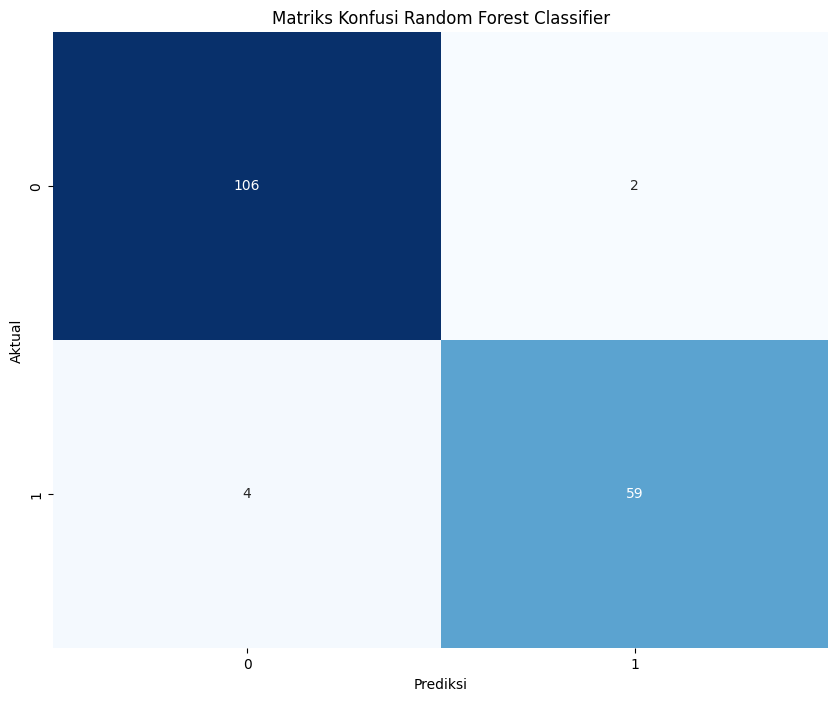


--- Pentingnya Fitur (Top 10) ---
7     0.144194
27    0.121969
23    0.094463
20    0.086314
6     0.085092
22    0.080638
2     0.059514
3     0.052266
26    0.039932
0     0.033731
dtype: float64


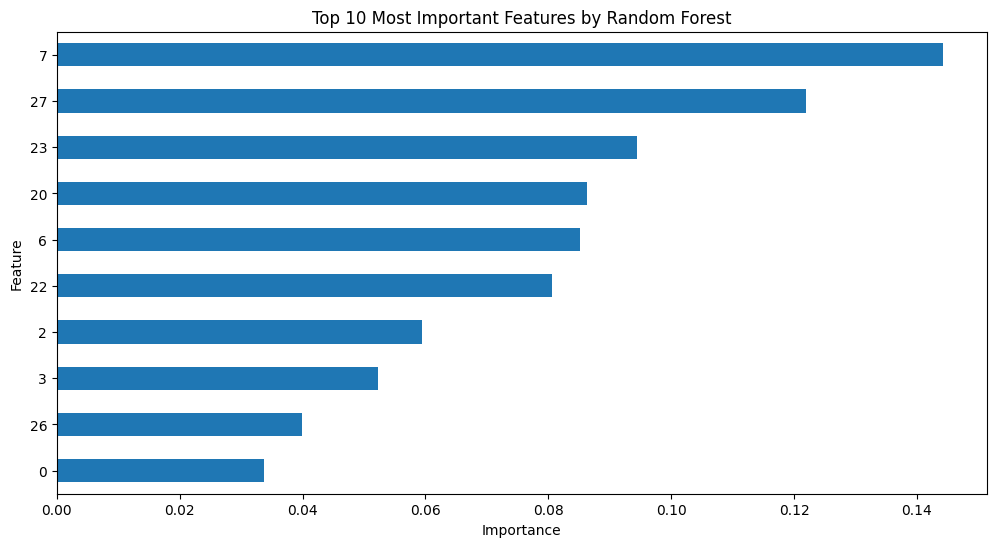

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize and train the Random Forest Classifier
print("\n--- Melatih Random Forest Classifier ---")
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 uses all available cores
rf_classifier.fit(X_train, y_train)
print("Random Forest Classifier berhasil dilatih.")

# Make predictions on the test set
y_pred = rf_classifier.predict(X_test)

# Evaluate the model
print("\n--- Evaluasi Model Random Forest Classifier ---")
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted') # Use 'weighted' for multi-class classification
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Akurasi: {accuracy:.4f}")
print(f"Presisi: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Display Confusion Matrix
print("\n--- Matriks Konfusi ---")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Matriks Konfusi Random Forest Classifier')
plt.show()

# Feature Importance (Optional, but good for understanding the model)
print("\n--- Pentingnya Fitur (Top 10) ---")
# Assuming X_train was originally a DataFrame to get feature names, or use column indices
# If X is an array, we don't have direct feature names, so we'll just use indices.
feature_importances = pd.Series(rf_classifier.feature_importances_)
if hasattr(X, 'columns'): # Check if original X had column names (if it was a DataFrame)
    feature_importances = pd.Series(rf_classifier.feature_importances_, index=df_dataset.drop('diagnosis', axis=1).columns)

top_10_features = feature_importances.nlargest(10)
print(top_10_features)

plt.figure(figsize=(12, 6))
top_10_features.plot(kind='barh')
plt.title('Top 10 Most Important Features by Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis() # Highest importance at the top
plt.show()


--- Melatih K-Nearest Neighbors (KNN) Classifier ---
KNN Classifier berhasil dilatih.

--- Evaluasi Model KNN Classifier ---
Akurasi (KNN): 0.9649
Presisi (KNN): 0.9649
Recall (KNN): 0.9649
F1-Score (KNN): 0.9649

--- Matriks Konfusi KNN Classifier ---


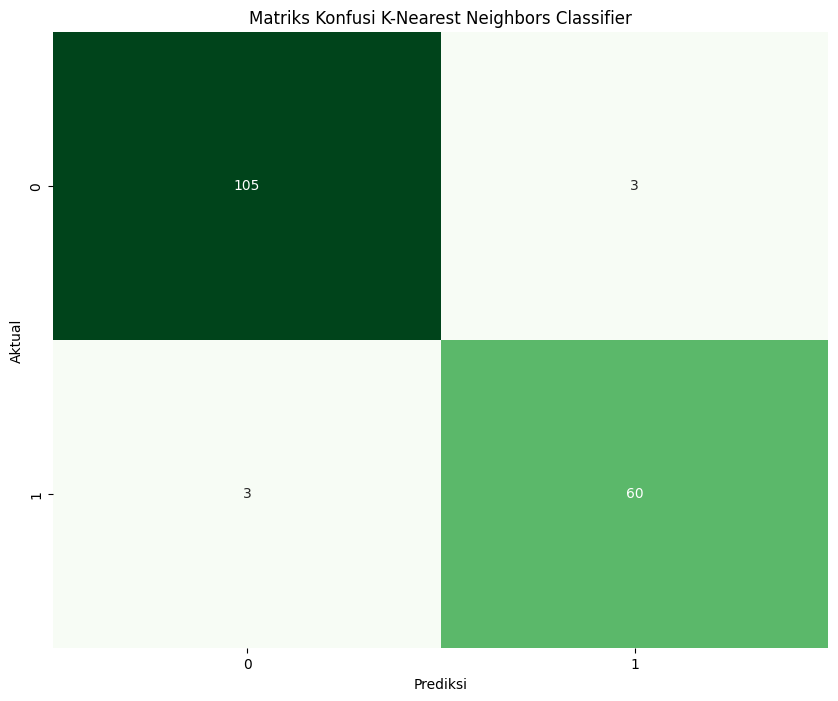


--- Melatih Support Vector Machine (SVM) Classifier ---
SVM Classifier berhasil dilatih.

--- Evaluasi Model SVM Classifier ---
Akurasi (SVM): 0.9883
Presisi (SVM): 0.9885
Recall (SVM): 0.9883
F1-Score (SVM): 0.9883

--- Matriks Konfusi SVM Classifier ---


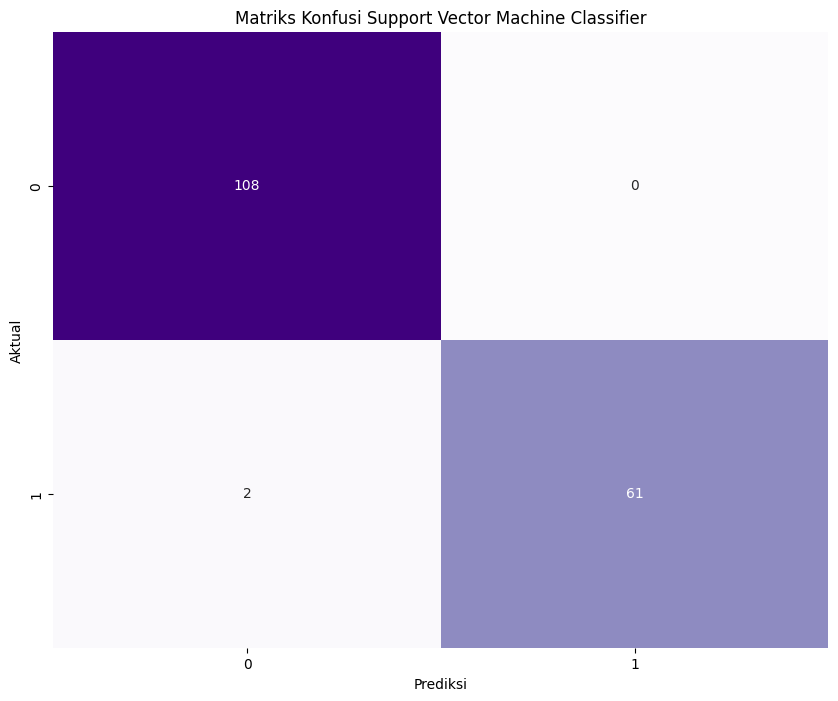

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from SVM convergence

# --- K-Nearest Neighbors (KNN) Classifier ---
print("\n--- Melatih K-Nearest Neighbors (KNN) Classifier ---")
# For simplicity, using default n_neighbors=5. You might want to optimize this.
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(X_train, y_train)
print("KNN Classifier berhasil dilatih.")

y_pred_knn = knn_classifier.predict(X_test)

print("\n--- Evaluasi Model KNN Classifier ---")
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, average='weighted')
recall_knn = recall_score(y_test, y_pred_knn, average='weighted')
f1_knn = f1_score(y_test, y_pred_knn, average='weighted')

print(f"Akurasi (KNN): {accuracy_knn:.4f}")
print(f"Presisi (KNN): {precision_knn:.4f}")
print(f"Recall (KNN): {recall_knn:.4f}")
print(f"F1-Score (KNN): {f1_knn:.4f}")

# Display Confusion Matrix for KNN
print("\n--- Matriks Konfusi KNN Classifier ---")
cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Matriks Konfusi K-Nearest Neighbors Classifier')
plt.show()

# --- Support Vector Machine (SVM) Classifier ---
print("\n--- Melatih Support Vector Machine (SVM) Classifier ---")
# Using a linear kernel for faster computation. RBF kernel is more powerful but slower.
# For large datasets, SVMs can be computationally expensive.
svm_classifier = SVC(kernel='linear', random_state=42)
svm_classifier.fit(X_train, y_train)
print("SVM Classifier berhasil dilatih.")

y_pred_svm = svm_classifier.predict(X_test)

print("\n--- Evaluasi Model SVM Classifier ---")
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print(f"Akurasi (SVM): {accuracy_svm:.4f}")
print(f"Presisi (SVM): {precision_svm:.4f}")
print(f"Recall (SVM): {recall_svm:.4f}")
print(f"F1-Score (SVM): {f1_svm:.4f}")

# Display Confusion Matrix for SVM
print("\n--- Matriks Konfusi SVM Classifier ---")
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Matriks Konfusi Support Vector Machine Classifier')
plt.show()